**Before starting this practical session**:

1. **Change the runtime type on Google Colab**: `Runtime > Change runtime type > T4 GPU`
2. **Install the packages below**:

In [ ]:
! pip install lightning torchmetrics torchinfo

3. Run this code to suppress some messages and warnings that may be displayed.

In [2]:
import logging
logging.getLogger("lightning").setLevel(logging.ERROR)
logging.getLogger("lightning.pytorch.utilities.rank_zero").setLevel(logging.WARNING)
logging.getLogger("lightning.pytorch.accelerators.cuda").setLevel(logging.WARNING)
logger = logging.getLogger("lightning")
logger.propagate = False

import warnings
warnings.filterwarnings("ignore", ".*does not have many workers.*")
warnings.filterwarnings("ignore", ".*Missing logger folder.*")
warnings.filterwarnings("ignore", "`isinstance\\(treespec, LeafSpec\\)` is deprecated.*")

# Image classification with a convolutional neural network

## Loading the data

We will work on a dataset called [EMNIST](https://www.westernsydney.edu.au/icns/resources/reproducible_research3/publication_support_materials2/emnist), and more specifically on a subset consisting of grayscale images of handwritten letters.
To do this, we will use the [`torchvision.datasets.EMNIST()`](https://pytorch.org/vision/stable/generated/torchvision.datasets.EMNIST.html) class to download and load this dataset.

In [3]:
import torch
from torchvision.datasets import EMNIST
from torchvision.transforms import v2


dataset_train = EMNIST(
    root="data",
    split="letters",
    download=True,
    train=True,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)]),
    target_transform=lambda x: x - 1
)

dataset_val = EMNIST(
    root="data",
    split="letters",
    download=True,
    train=False,
    transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)]),
    target_transform=lambda x: x - 1
)

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 562M/562M [00:17<00:00, 32.7MB/s]


### Question 1

**a)** Compute the size of the training and validation sets, i.e., the number of images in each of the two sets.

**b)** Compute the size of an observation, i.e., the size of an image. We will assume that all observations have the same size (this is indeed the case, you do not need to verify it).

In [4]:
print(f"Size of the training set = {len(dataset_train)}")
print(f"Size of the validation set = {len(dataset_val)}")

input_size = dataset_train[0][0].size()
print(f"Size of one image = {input_size}")

Size of the training set = 124800
Size of the validation set = 20800
Size of one image = torch.Size([1, 28, 28])


There are 26 classes in this dataset, corresponding to the 26 letters of the alphabet. However, the dataset mixes uppercase and lowercase letters: images for the letters *A* and *a* therefore have the same label.

The code below displays nine observations randomly drawn from the training set.

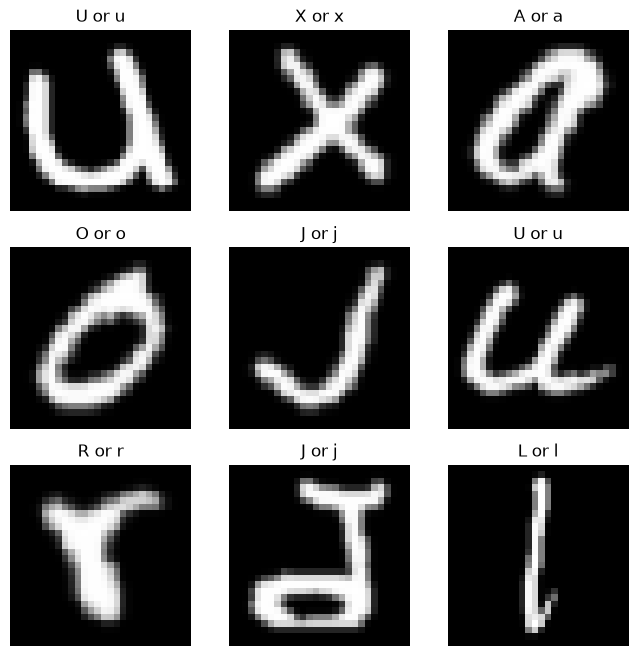

In [5]:
import matplotlib.pyplot as plt


figure = plt.figure(figsize=(8, 8))
cols, rows = 3, 3
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(dataset_train), size=(1,)).item()
    img, label = dataset_train[sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(f"{chr(65 + label)} or {chr(97 + label)}")
    plt.axis("off")
    plt.imshow(img.squeeze().T, cmap="gray")
plt.show()

### Question 2

You may have noticed the following code in the creation of the datasets:

```python
transform=v2.Compose([v2.ToImage(), v2.ToDtype(torch.float32, scale=True)]),
target_transform=lambda x: x - 1
```

By reading the documentation of the [`torchvision.datasets.EMNIST()`](https://pytorch.org/vision/stable/generated/torchvision.datasets.EMNIST.html) class, you will see that:
* the `transform` argument transforms the raw image,
* the `target_transform` argument transforms the label.

**a)** Explain the purpose of the code transforming the inputs. To do this, for the first observation of the training set, display the tensor of the raw input and the tensor of the transformed input. In particular, compare the size, the data type (*dtype*), and the minimum and maximum values for these two tensors.

> **Note**: you can access the raw data of this dataset through the `data` attribute (e.g., `dataset_train.data`)

**b)** Explain the purpose of the code transforming the labels.

> **Note**: you can access the raw label mapping of this dataset through the `class_to_idx` attribute (e.g., `dataset_train.class_to_idx`). You may assume, without verifying it, that there is no missing label (`'N/A'`) in either of the two datasets.

In [6]:
dataset_train.data[0]

tensor([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   1,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,  20, 114, 125,  82,  37,  37,  39, 115, 157,  94,  21,  10,
          32,  37,  37,  37,  37,  37,  37,  37,  82, 125, 114,  20,   0,   0],
        [  0,   3, 109, 245, 249, 233, 217, 217, 217, 245, 251, 234, 172, 142,
         203, 217, 217, 217, 217, 217, 217, 217, 233, 249, 245, 109,   3,   0],
        [  0,   4, 114, 253, 254, 254, 254, 254, 254, 254, 254, 254, 252, 251,
         254, 254, 254, 254, 254, 254, 254, 254, 254, 254, 254, 127,   4,   0],
        [  0,   0,  45, 214, 233, 251, 254, 25

In [7]:
dataset_train.data[0].dtype, dataset_train.data[0].min().item(), dataset_train.data[0].max().item()

(torch.uint8, 0, 255)

In [8]:
dataset_train[0][0]

Image([[[0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0039, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000],
        [0.0000, 0.0000, 0.0784, 0.4471, 0.4902, 0.3216, 0.1451, 0.1451, 0.1529,
         0.4510, 0.6157, 0.3686, 0.0824, 0.0392, 0.1255, 0.1451, 0.1451, 0.1451,
         0.1451, 0.1451, 0.1451, 0.1451, 0.3216, 0.4902

In [9]:
dataset_train[0][0].dtype, dataset_train[0][0].min().item(), dataset_train[0][0].max().item()

(torch.float32, 0.0, 1.0)

In [10]:
# Apply the label transformation to all the raw labels at once
# (much faster than iterating over the whole dataset)
sorted(set(dataset_train.target_transform(dataset_train.targets).tolist()))

[0,
 1,
 2,
 3,
 4,
 5,
 6,
 7,
 8,
 9,
 10,
 11,
 12,
 13,
 14,
 15,
 16,
 17,
 18,
 19,
 20,
 21,
 22,
 23,
 24,
 25]

In [11]:
dataset_train.class_to_idx

{'N/A': 0,
 'a': 1,
 'b': 2,
 'c': 3,
 'd': 4,
 'e': 5,
 'f': 6,
 'g': 7,
 'h': 8,
 'i': 9,
 'j': 10,
 'k': 11,
 'l': 12,
 'm': 13,
 'n': 14,
 'o': 15,
 'p': 16,
 'q': 17,
 'r': 18,
 's': 19,
 't': 20,
 'u': 21,
 'v': 22,
 'w': 23,
 'x': 24,
 'y': 25,
 'z': 26}

**Answers**:

**a)** `dataset_train.data[0]` corresponds to the original tensor of the input of the first sample (i.e., the first image). Its shape is $(28, 28)$ and it consists of integers ranging from 0 to 255 (corresponding to the set of unsigned (that is, non-negative) integers that can be defined with 8 bits, hence the `torch.uint8` data type). `dataset_train[0][0]` corresponds to the transformed tensor for the first image. Its shape is $(1, 28, 28)$ (a channel dimension has been added) and it consists of 32-bit floating-point numbers ranging from 0.0 to 1.0. **Data normalization is an important processing step in deep learning because of the limitations of [floating-point arithmetic](https://en.wikipedia.org/wiki/Floating-point_arithmetic)**.

**b)** `dataset_train[i][1]` is the label of the $i$-th training sample. Note that it is an integer instead of a string, even though the real labels are the 26 letters of the Latin alphabet. The attribute `dataset_train.class_to_idx` provides the mapping between the 26 letters and the indices. Notice that the indices range from $0$ to $25$, even though one might expect them to range from $1$ to $26$ based on the dictionary. The reason is that there is no missing label (`'N/A'`, index $0$) in the datasets and we subtract 1 from each index (`'a'` corresponds to $0$ and `'z'` corresponds to $25$).

### Question 3

Compute the class distribution on the training and validation sets. Are the classes balanced? Is accuracy an appropriate metric for evaluating a model's performance?

> **Remark**: You can use one of the following functions to compute the distribution of an array or a tensor of non-negative integers: [`numpy.unique()`](https://numpy.org/doc/stable/reference/generated/numpy.unique.html), [`numpy.bincount()`](https://numpy.org/doc/stable/reference/generated/numpy.bincount.html) or [`torch.bincount()`](https://pytorch.org/docs/stable/generated/torch.bincount.html).

In [12]:
import numpy as np

# Use the raw labels directly (much faster than iterating over the whole dataset)
_, counts_train = np.unique(dataset_train.target_transform(dataset_train.targets).numpy(), return_counts=True)
print(f"Class distribution on the training set: {counts_train}")

_, counts_val = np.unique(dataset_val.target_transform(dataset_val.targets).numpy(), return_counts=True)
print(f"Class distribution on the validation set: {counts_val}")

Class distribution on the training set: [4800 4800 4800 4800 4800 4800 4800 4800 4800 4800 4800 4800 4800 4800
 4800 4800 4800 4800 4800 4800 4800 4800 4800 4800 4800 4800]
Class distribution on the validation set: [800 800 800 800 800 800 800 800 800 800 800 800 800 800 800 800 800 800
 800 800 800 800 800 800 800 800]


**Answer**: The classes are perfectly balanced: there are $4,800$ images per class in the training set and $800$ images per class in the validation set. Accuracy is therefore an appropriate metric.

### Question 4

Build the *dataloaders* for the training and validation sets. Use batches of size *64*. Shuffle the observations on the training set.

In [13]:
from torch.utils.data import DataLoader


batch_size = 64
dataloader_train = DataLoader(dataset_train, batch_size=batch_size, shuffle=True)
dataloader_val = DataLoader(dataset_val, batch_size=batch_size)

## A first convolutional neural network

### Question 5

The following code is a draft definition of a convolutional neural network. Answer the following questions:

**a)** Which layers are convolutional layers?

**b)** Why is the number of input channels set to `1` in `self.cv1`?

**c)** Indicate, for `self.cv1`, the number of output channels, the kernel size, and the stride.

**d)** What type of pooling layer does this network consist of?

**e)** Which layers have trainable parameters?

In [14]:
import lightning as L
from torchmetrics import Accuracy


class CNN(L.LightningModule):  # Always inherit from the lightning.LightningModule class
    def __init__(self):
        """Constructor.
        
        In the constructor, we always run the constructor of the parent class and we
        instantiate all the elements of our network: the layers, the activation functions,
        the loss function and the metrics.
        """
        super().__init__()  # Always run the constructor of the parent class
        
        # Instantiate the layers and activation functions
        self.cv1 = torch.nn.Conv2d(in_channels=1, out_channels=4, kernel_size=5, padding="same")
        self.relu1 = torch.nn.ReLU()
        self.pool1 = torch.nn.MaxPool2d(kernel_size=2, stride=2)
        self.flatten = torch.nn.Flatten()
        self.fc2 = torch.nn.Linear(784, 64)
        self.relu2 = torch.nn.ReLU()
        self.fc3 = torch.nn.Linear(64, 26)
        
        # Instantiate the loss function
        self.loss = torch.nn.CrossEntropyLoss()
        
        # Instantiate the metrics
        self.accuracy_train = Accuracy(task="multiclass", num_classes=26)
        self.accuracy_val = Accuracy(task="multiclass", num_classes=26)
    
    def forward(self, x):
        """Implements the forward pass."""
        out = self.cv1(x)
        out = self.relu1(out)
        out = self.pool1(out)
        out = self.flatten(out)
        out = self.fc2(out)
        out = self.relu2(out)
        out = self.fc3(out)
        return out
    
    def step(self, batch, dataset):
        """Perform a step.
        
        A step consists in mapping a batch of samples to the loss function for this batch of input samples.

        Parameters
        ----------
        batch : tuple
            A batch of samples.
            
        dataset : {"training", "validation"}
            Data set used.

        Returns
        -------
        loss : Tensor, shape = (1,)
            Loss function evaluated for this batch of samples.
        """
        x, y = batch  # x corresponds to the images, y to the classes (labels)
        logits = self(x)  # Forward pass outputting the logits
        loss = self.loss(logits, y)  # Evaluation of the loss function
        y_pred = logits.argmax(1)  # Predictions of the model
        
        if dataset == "training":
            metric = self.accuracy_train
            name = "train"
            bar_step = True
        else:
            metric = self.accuracy_val
            name = "val"
            bar_step = False

        acc = metric(y_pred, y)
        self.log(f"loss_{name}", loss, prog_bar=bar_step, on_step=bar_step, on_epoch=True)
        self.log(f"accuracy_{name}", acc, prog_bar=bar_step, on_step=bar_step, on_epoch=True)
        
        return loss
    
    def training_step(self, batch):
        """Perform a training step."""
        return self.step(batch, "training")

    def validation_step(self, batch):
        """Perform a validation step."""
        return self.step(batch, "validation")
    
    def on_train_start(self):
        """Code to run at the beginning of training."""
        string = f"Version {self.trainer.logger.version}"
        print(f"{string}\n{'=' * len(string)}\n")
    
    def on_train_epoch_end(self):
        """Code to run at the end of each training epoch."""
        metrics = self.trainer.callback_metrics
        string = (f"""
            Epoch {self.trainer.current_epoch + 1} / {self.trainer.max_epochs}
            -----------------------------------------
            |  Data set  | Loss function | Accuracy |
            | ---------- | ------------- | -------- |
            |  Training  |{metrics['loss_train'].item():^15.5f}|{metrics['accuracy_train'].item():^10.4%}|
            | Validation |{metrics['loss_val'].item():^15.5f}|{metrics['accuracy_val'].item():^10.4%}|
            -----------------------------------------
        """)
        string = "\n".join([line.strip() for line in string.strip().split("\n")])
        print(string, "\n")

    def configure_optimizers(self):
        """Configure the optimization algorithms."""
        optimizer = torch.optim.Adam(self.parameters())
        return optimizer

**Answers**:

**a)** There is only one convolutional layer: `cv1`.

**b)** The input images are grayscale images, hence the single input channel.

**c)** There are 4 output channels, the kernel size is $5 \times 5$ and the stride is $1$.

**d)** There is only one pooling layer: `pool1`. It is a maximum pooling layer.

**e)** The layers with trainable parameters are the convolution layer (`cv1`) and the linear layers (`fc2` and `fc3`). The flattening and pooling layers have no trainable parameters, neither does the ReLU activation function.

### Question 6

When trying to display the architecture summary of our model with the code below, an error will be raised. Identify the problem corresponding to this error and fix it. Explain, in words, what the problem was.

In [15]:
from torchinfo import summary


summary(CNN(), input_size=(batch_size, *input_size))

Layer (type:depth-idx)                   Output Shape              Param #
CNN                                      [64, 26]                  --
├─Conv2d: 1-1                            [64, 4, 28, 28]           104
├─ReLU: 1-2                              [64, 4, 28, 28]           --
├─MaxPool2d: 1-3                         [64, 4, 14, 14]           --
├─Flatten: 1-4                           [64, 784]                 --
├─Linear: 1-5                            [64, 64]                  50,240
├─ReLU: 1-6                              [64, 64]                  --
├─Linear: 1-7                            [64, 26]                  1,690
Total params: 52,034
Trainable params: 52,034
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 8.54
Input size (MB): 0.20
Forward/backward pass size (MB): 1.65
Params size (MB): 0.21
Estimated Total Size (MB): 2.06

**Answer**: The size of the vector (after flattening) is equal to the product between the number of channels and the number of pixels, that is $4 \times 14 \times 14 = 784$ instead of $123$.

### Question 7

Train your model for 10 epochs. Compare the model's performance to that expected for a trivial model (which would always predict the same class or would predict classes completely randomly).

In [16]:
from lightning.pytorch.callbacks import TQDMProgressBar
from lightning.pytorch.loggers import CSVLogger


model = CNN()

trainer = L.Trainer(
    max_epochs=10,
    enable_model_summary=False,  # disable model summary
    logger=CSVLogger('.'),  # save the results in a CSV file
    num_sanity_val_steps=0,  # do not perform any validation step before training
    callbacks=[TQDMProgressBar(refresh_rate=100)]  # update the progress bar every 100 batches
)

trainer.fit(
    model=model,
    train_dataloaders=dataloader_train,
    val_dataloaders=dataloader_val
)

Training: |                                                                                                   …

Version 0



Validation: |                                                                                                 …

Epoch 1 / 10
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.81859    | 75.7035% |
| Validation |    0.52432    | 83.7260% |
----------------------------------------- 



Validation: |                                                                                                 …

Epoch 2 / 10
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.44632    | 86.0849% |
| Validation |    0.41373    | 87.2404% |
----------------------------------------- 



... (12 outputs left out)

Validation: |                                                                                                 …

Epoch 9 / 10
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.26128    | 91.4760% |
| Validation |    0.30277    | 90.3846% |
----------------------------------------- 



Validation: |                                                                                                 …

Epoch 10 / 10
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.25270    | 91.7011% |
| Validation |    0.32052    | 90.0529% |
----------------------------------------- 



**Answer**: The performance of the model is pretty good, with around 90% accuracy. **We did not fix the random seed, so the performance may vary with different runs**. Since the classes are balanced, a completely random model has a 1 in 26 chance of predicting the correct class: its expected accuracy is $1/26 \approx 3.85\%$. A model always predicting the same class has the same expected accuracy. Our model performs much better than these trivial models.

### Question 8

Visualize the model's performance curves using the `plot_loss_accuracy` function defined below. You can use the `version` argument to indicate which version of the model to choose.

In [17]:
def plot_loss_accuracy(savedir=".", version=None):
    """Plot the loss function and accuracy curves.
    
    Parameters
    ----------
    savedir : str (default = ".")
        Path to the results.
        
    version : int or None (default = None)
        Version number of the model.
    """
    # Get the results as a pandas.DataFrame
    import os
    import pandas as pd
    if version is None:
        version = max([
            int(folder.split("version_")[1])
            for folder in os.listdir(os.path.join(savedir, "lightning_logs"))
            if folder.startswith("version")
        ])
    df = pd.read_csv(os.path.join(savedir, "lightning_logs", f"version_{version}", "metrics.csv"))
    df["epoch"] += 1  # Start counting the epochs from 1 instead of 0

    loss_train = df.dropna(subset="loss_train_epoch").set_index("epoch")["loss_train_epoch"]
    loss_val = df.dropna(subset="loss_val").set_index("epoch")["loss_val"]

    accuracy_train = df.dropna(subset="accuracy_train_epoch").set_index("epoch")["accuracy_train_epoch"]
    accuracy_val = df.dropna(subset="accuracy_val").set_index("epoch")["accuracy_val"]

    # Plot the results
    plt.figure(figsize=(13, 4))

    plt.subplot(1, 2, 1)
    plt.plot(loss_train.index, loss_train.to_numpy(), "o-", label="Training");
    plt.plot(loss_val.index, loss_val.to_numpy(), "o-", label="Validation");
    plt.xlabel("Epoch")
    plt.ylabel("Loss function")
    plt.legend();

    plt.subplot(1, 2, 2)
    plt.plot(accuracy_train.index, accuracy_train.to_numpy(), "o-", label="Training");
    plt.plot(accuracy_val.index, accuracy_val.to_numpy(), "o-", label="Validation");
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend();

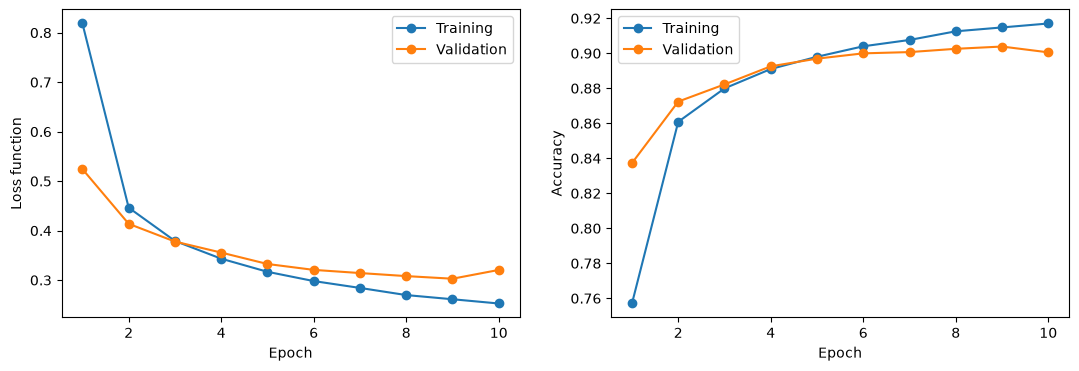

In [18]:
plot_loss_accuracy()

## A second convolutional neural network

### Question 9

Complete the `__init__()` method of the `LeNet5` class defined below, whose sequential architecture is described below, corresponding to the [LeNet5](https://en.wikipedia.org/wiki/LeNet) architecture:

* a convolutional layer with $6$ output channels, a kernel of size $5 \times 5$, and padding such that the output image has the same size as the input image.
* the sigmoid activation function.
* a max pooling layer with a kernel of size $2 \times 2$ and a stride of $2$.
* a convolutional layer with $16$ output channels, a kernel of size $5 \times 5$, and no padding.
* the sigmoid activation function.
* a max pooling layer with a kernel of size $2 \times 2$ and a stride of $2$.
* a flatten layer.
* a linear layer with an input of size $400$ and an output of size $256$.
* the sigmoid activation function.
* a linear layer with an output of size $128$.
* the sigmoid activation function.
* a linear layer with an output of size $26$.

Here are the links to the documentation of the corresponding classes:
[`torch.nn.Conv2d()`](https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html),
[`torch.nn.Sigmoid()`](https://pytorch.org/docs/stable/generated/torch.nn.Sigmoid.html),
[`torch.nn.MaxPool2d()`](https://pytorch.org/docs/stable/generated/torch.nn.MaxPool2d.html),
[`torch.nn.Flatten()`](https://pytorch.org/docs/stable/generated/torch.nn.Flatten.html), and
[`torch.nn.Linear()`](https://pytorch.org/docs/stable/generated/torch.nn.Linear.html).

In [19]:
class LeNet5(L.LightningModule):  # Always inherit from the lightning.LightningModule class
    def __init__(self):
        """Constructor.
        
        In the constructor, we always run the constructor of the parent class and we
        instantiate all the elements of our network: the layers, the activation functions,
        the loss function and the metrics.
        """
        super().__init__()  # Always run the constructor of the parent class
        
        ### BEGIN TODO ###
        # Instantiate the layers and the activation functions
        self.sequential = torch.nn.Sequential(
            # First convolutional layer
            torch.nn.Conv2d(1, 6, kernel_size=5, padding='same'),
            torch.nn.Sigmoid(),
            torch.nn.MaxPool2d(kernel_size=2, stride=2),
            
            # Second convolutional layer
            torch.nn.Conv2d(6, 16, kernel_size=5, padding=0),
            torch.nn.Sigmoid(),
            torch.nn.MaxPool2d(kernel_size=2, stride=2),
            
            # Flattening then multilayer perceptron
            torch.nn.Flatten(),
            torch.nn.Linear(400, 256),
            torch.nn.Sigmoid(),
            torch.nn.Linear(256, 128),
            torch.nn.Sigmoid(),
            torch.nn.Linear(128, 26)
        )
        #### END TODO ####
        
        # Instantiate the loss function
        self.loss = torch.nn.CrossEntropyLoss()
        
        # Instantiate the metrics
        self.accuracy_train = Accuracy(task="multiclass", num_classes=26)
        self.accuracy_val = Accuracy(task="multiclass", num_classes=26)
    
    def forward(self, x):
        """Implements the forward pass."""
        ### BEGIN TODO ###
        y = self.sequential(x)
        #### END TODO ####
        return y
    
    def step(self, batch, dataset):
        """Perform a step.
        
        A step consists in mapping a batch of samples to the loss function for this batch of input samples.

        Parameters
        ----------
        batch : tuple
            A batch of samples.
            
        dataset : {"training", "validation"}
            Data set used.

        Returns
        -------
        loss : Tensor, shape = (1,)
            Loss function evaluated for this batch of samples.
        """

        x, y = batch  # x corresponds to the images, y to the classes (labels)
        logits = self(x)  # Forward pass outputting the logits
        loss = self.loss(logits, y)  # Evaluation of the loss function
        y_pred = logits.argmax(1)  # Predictions of the model
        
        if dataset == "training":
            metric = self.accuracy_train
            name = "train"
            bar_step = True
        else:
            metric = self.accuracy_val
            name = "val"
            bar_step = False

        acc = metric(y_pred, y)
        self.log(f"loss_{name}", loss, prog_bar=bar_step, on_step=bar_step, on_epoch=True)
        self.log(f"accuracy_{name}", acc, prog_bar=bar_step, on_step=bar_step, on_epoch=True)
        
        return loss
    
    def training_step(self, batch):
        """Perform a training step."""
        return self.step(batch, "training")

    def validation_step(self, batch):
        """Perform a validation step."""
        return self.step(batch, "validation")
    
    def on_train_start(self):
        """Code to run at the beginning of the training."""
        string = f"Version {self.trainer.logger.version}"
        print(f"{string}\n{'=' * len(string)}\n")
    
    def on_train_epoch_end(self):
        """Code to run at the end of each training epoch."""
        metrics = self.trainer.callback_metrics
        string = (f"""
            Epoch {self.trainer.current_epoch + 1} / {self.trainer.max_epochs}
            -----------------------------------------
            |  Data set  | Loss function | Accuracy |
            | ---------- | ------------- | -------- |
            |  Training  |{metrics['loss_train'].item():^15.5f}|{metrics['accuracy_train'].item():^10.3%}|
            | Validation |{metrics['loss_val'].item():^15.5f}|{metrics['accuracy_val'].item():^10.3%}|
            -----------------------------------------
        """)
        string = "\n".join([line.strip() for line in string.strip().split("\n")])
        print(string, "\n")

    def configure_optimizers(self):
        """Configure the optimization algorithms."""
        optimizer = torch.optim.Adam(self.parameters())
        return optimizer

### Question 10

Display a summary of this architecture. How many trainable parameters does this architecture have?

In [20]:
summary(LeNet5(), input_size=(batch_size, *input_size))

Layer (type:depth-idx)                   Output Shape              Param #
LeNet5                                   [64, 26]                  --
├─Sequential: 1-1                        [64, 26]                  --
│    └─Conv2d: 2-1                       [64, 6, 28, 28]           156
│    └─Sigmoid: 2-2                      [64, 6, 28, 28]           --
│    └─MaxPool2d: 2-3                    [64, 6, 14, 14]           --
│    └─Conv2d: 2-4                       [64, 16, 10, 10]          2,416
│    └─Sigmoid: 2-5                      [64, 16, 10, 10]          --
│    └─MaxPool2d: 2-6                    [64, 16, 5, 5]            --
│    └─Flatten: 2-7                      [64, 400]                 --
│    └─Linear: 2-8                       [64, 256]                 102,656
│    └─Sigmoid: 2-9                      [64, 256]                 --
│    └─Linear: 2-10                      [64, 128]                 32,896
│    └─Sigmoid: 2-11                     [64, 128]                 --
│ 

**Answer**: This architecture has $141,478$ trainable parameters.

### Question 11

Train your new neural network for 10 epochs. Compare its performance to that of the previous model.

In [21]:
model_lenet = LeNet5()

trainer_lenet = L.Trainer(
    max_epochs=10,
    enable_model_summary=False,  # disable model summary
    logger=CSVLogger('.'),  # save the results in a CSV file
    num_sanity_val_steps=0,  # do not perform any validation step before training
    callbacks=[TQDMProgressBar(refresh_rate=100)]  # update the progress bar every 100 batches
)

trainer_lenet.fit(
    model=model_lenet,
    train_dataloaders=dataloader_train,
    val_dataloaders=dataloader_val
)

Training: |                                                                                                   …

Version 1



Validation: |                                                                                                 …

Epoch 1 / 10
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    1.51678    | 55.020%  |
| Validation |    0.70415    | 78.803%  |
----------------------------------------- 



Validation: |                                                                                                 …

Epoch 2 / 10
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.52343    | 83.850%  |
| Validation |    0.42706    | 86.841%  |
----------------------------------------- 



... (12 outputs left out)

Validation: |                                                                                                 …

Epoch 9 / 10
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.19434    | 93.377%  |
| Validation |    0.24085    | 92.178%  |
----------------------------------------- 



Validation: |                                                                                                 …

Epoch 10 / 10
-----------------------------------------
|  Data set  | Loss function | Accuracy |
| ---------- | ------------- | -------- |
|  Training  |    0.18265    | 93.755%  |
| Validation |    0.22736    | 92.687%  |
----------------------------------------- 



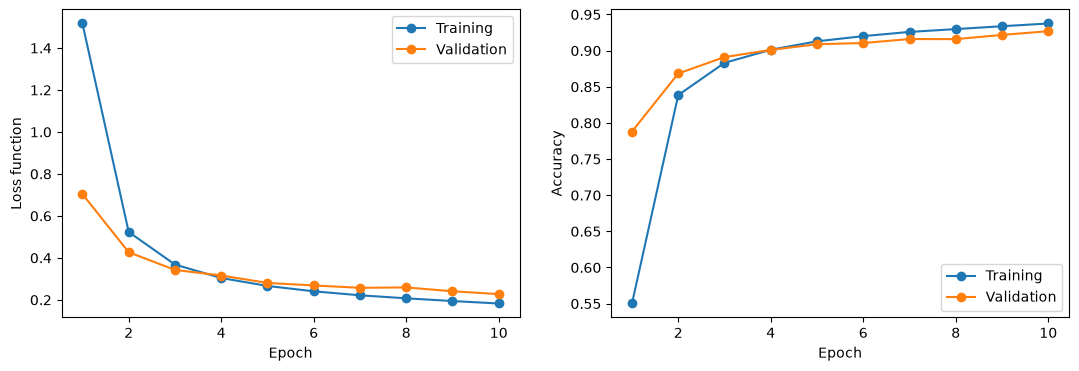

In [22]:
plot_loss_accuracy()

**Answer**: This more complex model ($141,478$ trainable parameters compared to $52,034$ for the first one), with more convolutional layers, performs slightly better.